<a href="https://colab.research.google.com/github/rtbn12/dap-2024/blob/main/les06/%D0%9B%D0%B0%D0%B1%D0%A0%D0%B0%D0%B1_6_%D0%A1%D0%BE%D0%BB%D0%BE%D0%B4%D0%BE%D0%B2_12002408.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

БЕЛГОРОДСКИЙ ГОСУДАРСТВЕННЫЙ НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ» (НИУ «БелГУ») ИНСТИТУТ ИНЖЕНЕРНЫХ И ЦИФРОВЫХ ТЕХНОЛОГИЙ Кафедра информационных и робототехнических систем

Отчет по лабораторной работе № 6 Тема работы: Линейная регрессия

«Анализ данных на Python»

студента очного отделения 3 курса группы 12002408

Солодова Егора Николаевича

Проверил: ассистент Пузырёв Никита Сергеевич

БЕЛГОРОД 2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


**Извлечение данных**

In [3]:
from sklearn import datasets
diabetes = datasets.load_diabetes()
print(diabetes)

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]], shape=(442, 10)), 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59

Выведете описание набора данных и наименование признаков.

In [4]:
print(diabetes.DESCR)
print(diabetes.feature_names)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

**Подготовка данных**

Из загруженного набора данных создайте DataFrame, содержащий как признаки, так и целевое значение. Выведите первые 5 строк набора.

In [5]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target
print(df.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


Выведете информацию о типах данных в наборе. Имеются ли в наборе категориальные признаки? Имеются ли в наборе данные имеющие значение null?

In [6]:
print(df.info())
print(df.dtypes)
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


Что реально означают признаки
Расшифровка из оригинальной статьи (Efron et al., 2004):

age — возраст в годах (стандартизирован)

sex — пол (0 = женщина, 1 = мужчина, стандартизирован)

bmi — индекс массы тела (вес / рост², кг/м²)

bp — среднее артериальное давление (мм рт.ст.)

s1 — TC, общий холестерин сыворотки (ммоль/л)

s2 — LDL, липопротеины низкой плотности («плохой» холестерин)

s3 — HDL, липопротеины высокой плотности («хороший» холестерин)

s4 — TCH, отношение общего холестерина к HDL

s5 — LTG, логарифм триглицеридов сыворотки

s6 — GLU, уровень глюкозы в крови

target — количественный показатель прогрессирования диабета через год после начала наблюдения. По сути это насколько болезнь ухудшилась за год по комплексной медицинской шкале. Больше = хуже.

**Исследование данных**

Постройте матрицу корреляции.

In [7]:
corr_matrix = df.corr()
print(corr_matrix.round(2))

         age   sex   bmi    bp    s1    s2    s3    s4    s5    s6  target
age     1.00  0.17  0.19  0.34  0.26  0.22 -0.08  0.20  0.27  0.30    0.19
sex     0.17  1.00  0.09  0.24  0.04  0.14 -0.38  0.33  0.15  0.21    0.04
bmi     0.19  0.09  1.00  0.40  0.25  0.26 -0.37  0.41  0.45  0.39    0.59
bp      0.34  0.24  0.40  1.00  0.24  0.19 -0.18  0.26  0.39  0.39    0.44
s1      0.26  0.04  0.25  0.24  1.00  0.90  0.05  0.54  0.52  0.33    0.21
s2      0.22  0.14  0.26  0.19  0.90  1.00 -0.20  0.66  0.32  0.29    0.17
s3     -0.08 -0.38 -0.37 -0.18  0.05 -0.20  1.00 -0.74 -0.40 -0.27   -0.39
s4      0.20  0.33  0.41  0.26  0.54  0.66 -0.74  1.00  0.62  0.42    0.43
s5      0.27  0.15  0.45  0.39  0.52  0.32 -0.40  0.62  1.00  0.46    0.57
s6      0.30  0.21  0.39  0.39  0.33  0.29 -0.27  0.42  0.46  1.00    0.38
target  0.19  0.04  0.59  0.44  0.21  0.17 -0.39  0.43  0.57  0.38    1.00


Постройте диаграмму рассеяния целевого значение и признака, коэффициент корреляции которого с целевым значением, самый высокий.

Самый коррелирующий признак: bmi, r = 0.5865


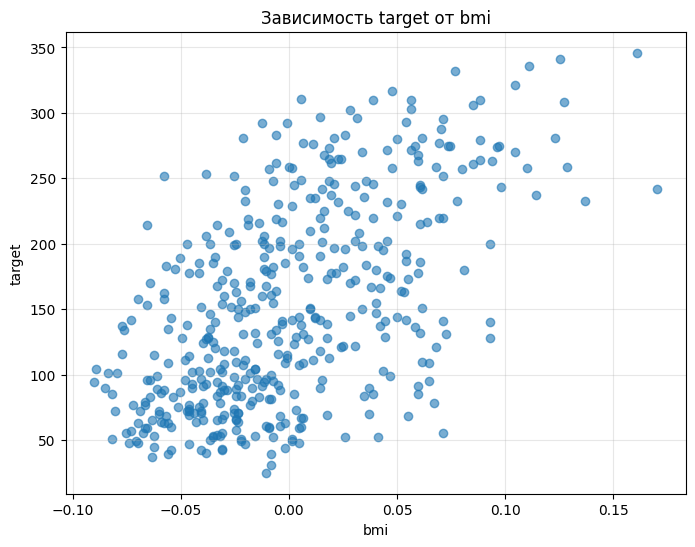

In [9]:
corr_with_target = corr_matrix['target'].drop('target')
top_feature = corr_with_target.abs().idxmax()
print(f"Самый коррелирующий признак: {top_feature}, r = {corr_with_target[top_feature]:.4f}")

plt.figure(figsize=(8, 6))
plt.scatter(df[top_feature], df['target'], alpha=0.6)
plt.xlabel(top_feature)
plt.ylabel('target')
plt.title(f'Зависимость target от {top_feature}')
plt.grid(True, alpha=0.3)
plt.show()

Сформируйте набор признаков (X) из 5 признаков с самым высоким коэффициентом корреляции с целевым значением. Сформируйте набор для целевого значения (y).

In [10]:
top5_features = corr_with_target.abs().sort_values(ascending=False).head(5).index.tolist()
print(f"Топ-5 признаков: {top5_features}")

X = df[top5_features]
y = df['target']

print(X.head())
print(y.head())

Топ-5 признаков: ['bmi', 's5', 'bp', 's4', 's3']
        bmi        s5        bp        s4        s3
0  0.061696  0.019907  0.021872 -0.002592 -0.043401
1 -0.051474 -0.068332 -0.026328 -0.039493  0.074412
2  0.044451  0.002861 -0.005670 -0.002592 -0.032356
3 -0.011595  0.022688 -0.036656  0.034309 -0.036038
4 -0.036385 -0.031988  0.021872 -0.002592  0.008142
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64


**Предсказательная модель**

Разделите набор данных на два, одни для обучения модели другой для проверки. Тестовый набор должен содержать 25 процентов данных.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=67
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")

X_train: (331, 5), y_train: (331,)
X_test:  (111, 5),  y_test:  (111,)


Выполните обучение модели.

In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Коэффициенты: {model.coef_}")
print(f"Свободный член: {model.intercept_}")

Коэффициенты: [ 609.24574936  475.74921041  255.73399199  -61.46019845 -263.05973611]
Свободный член: 151.33423237397548


**Проверка модели**

Расчитайте Root mean squared error (RMSE)

In [17]:
from sklearn import metrics

y_pred = model.predict(X_test)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
print(f"RMSE = {rmse:.4f}")

RMSE = 49.1653


Расчитайте R² (коэффициент детерминации)

In [18]:
r2 = metrics.r2_score(y_test, y_pred)
print(f"R² = {r2:.4f}")

R² = 0.5221


**Вывод:** RMSE = 49.17 — модель в среднем ошибается на 49 баллов прогрессирования диабета. При диапазоне target 25–346 (размах 321) это ~15% от размаха. Приемлемо.

R² = 0.5221 — модель объясняет 52% дисперсии target. Остальные 48% — шум и факторы, не учтённые в 5 признаках. Это лучше среднего (0.3–0.5 — слабо, 0.5–0.7 — приемлемо).

**Вывод:** в ходе выполнения лабораторной работы было проведено изучение построения линейной регресси с целью поиска наиболее влияющих на развитие диабета факторов.
Модель линейной регрессии, обученная на 5 признаках (bmi, s5, bp, s4, s3), показала RMSE = 49.17 и R² = 0.52 на тестовой выборке (25% данных). Это означает, что модель объясняет 52% дисперсии прогрессирования диабета и в среднем ошибается на 49 баллов. Модель значительно лучше наивного предсказания средним (RMSE ≈ 77), но качество умеренное — почти половина разброса осталась необъяснённой.

**Ответы на контрольные вопросы:**


**Какие типы машинного обучения вы знаете?**
Типы машинного обучения: с учителем, без учителя, частичное обучение, обучение с подкреплением.

**Чем отличается обучение с учителем и без учителя?**
С учителем vs без: с учителем есть размеченные данные (метки y), модель учится предсказывать ответ. Без учителя меток нет, модель ищет структуру в данных (кластеры, снижение размерности).

**Чем пакетное обучение отличается от динамического?**
Пакетное vs динамическое: пакетное учится сразу на всех данных, раз и навсегда, потом только применяет знания. Динамическое дообучается постепенно по мере поступления новых данных.

**Чем обучение на основе образцов отличается от обучения на основе модели?**
На основе образцов vs моделей: обучение на основе образцов запоминает примеры и сравнивает с ними новые (kNN). Обучение на основе моделей строит обобщающую формулу/модель (линейная регрессия, дерево).

**Что такое линейная регрессия?**
Линейная регрессия: модель вида y = w₁x₁ + ... + wₙxₙ + b, которая ищет линейную зависимость между признаками и целевым числовым значением, минимизируя сумму квадратов ошибок.

**Что такое градиентный спуск?**
Градиентный спуск: итеративный метод поиска минимума функции потерь — шагаем в сторону, противоположную градиенту, с шагом learning_rate, пока не сойдёмся.

**Как правильно обрабатывать категориальные признаки?**
Категориальные признаки: кодировать в числа — one-hot encoding (pd.get_dummies), label encoding (LabelEncoder) или target encoding. Линейная регрессия не работает со строками напрямую.

**Что такое матрица корреляции?**
Матрица корреляции: таблица коэффициентов Пирсона между всеми парами столбцов, показывает силу (-1 до 1) и направление линейной связи.

**Что показывает метрика RMSE?**
RMSE: среднеквадратичная ошибка в единицах целевого значения — показывает, насколько в среднем предсказание отличается от реальности.

**Что показывает метрика R²?**

R²: коэффициент детерминации — показывает, какую долю дисперсии целевого значения объясняет модель (от 0 до 1, может быть отрицательным при плохой модели).